#### 1. Data Extraction from BigQuery

In [ ]:
# Extraction from BigQuery
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
client = bigquery.Client(project="portofolio-494904")

query = """
SELECT *
FROM `portofolio-494904.socialmedia.social_media_enriched`
"""

df = client.query(query).to_dataframe()
df.head()

,user_id,age,gender,country,profession,primary_platform,platforms_used_count,daily_usage_hours,sessions_per_day,avg_session_duration_min,...,influencer_status,account_join_date,mood_while_scrolling,takes_social_media_breaks,user_segment,total_engagement,session_category,cleaned_time,age_group,spending_category
0,USR00542,17,Male,Canada,Designer,Pinterest,4,3.1,1,186.0,...,false,2023-07-24,Relaxed,<NA>,Medium,36.0,Low,6-10am,13-17,Low Spender
1,USR01341,28,Male,Canada,Engineer,Twitter/X,2,0.5,2,15.0,...,false,2024-11-04,Inspired,<NA>,Light,20.0,Low,6-10am,25-34,Medium Spender
2,USR00257,37,Female,USA,Teacher,Instagram,4,1.0,2,30.0,...,false,2024-12-03,Stressed,<NA>,Light,33.0,Low,9pm-12am,35-44,Low Spender
3,USR01571,33,Female,India,Other,Pinterest,1,1.8,2,54.0,...,false,2024-12-10,Neutral,<NA>,Light,39.0,Low,9pm-12am,25-34,Low Spender
4,USR01628,37,Female,UK,Doctor,Twitter/X,4,0.9,3,18.0,...,false,2023-11-11,Inspired,<NA>,Light,27.0,Low,6-9pm,35-44,Medium Spender


In [ ]:
# Import Library
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#### 2. Data Understanding

In [ ]:
# Data Types, Shape, Info, Summary Statistic Numeric
df.dtypes
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 40 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   user_id                            2000 non-null   object 
 1   age                                2000 non-null   Int64  
 2   gender                             2000 non-null   object 
 3   country                            2000 non-null   object 
 4   profession                         2000 non-null   object 
 5   primary_platform                   2000 non-null   object 
 6   platforms_used_count               2000 non-null   Int64  
 7   daily_usage_hours                  2000 non-null   float64
 8   sessions_per_day                   2000 non-null   Int64  
 9   avg_session_duration_min           2000 non-null   float64
 10  preferred_device                   2000 non-null   object 
 11  peak_usage_time                    2000 non-null   objec

,age,platforms_used_count,daily_usage_hours,sessions_per_day,avg_session_duration_min,followers_count,following_count,posts_per_week,likes_given_per_day,comments_per_day,shares_per_day,dms_sent_per_day,ad_click_rate,monthly_spend_via_social_usd,sleep_disruption,self_reported_mental_health_score,total_engagement
count,2000.0,2000.0,2000.000000,2000.0,2000.000000,2000.0,2000.0,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,0.0,2000.00000,2000.00000
mean,26.986,3.01,2.990650,5.0245,47.547400,4153.7375,513.9985,2.964000,19.883000,3.991500,1.988500,8.02600,0.130048,22.618225,NaN,6.17115,33.88900
std,7.649775,1.431756,1.858501,2.249985,51.104393,47935.625651,851.8179,1.679915,4.389527,1.997354,1.413636,2.77618,0.094675,33.884331,NaN,1.74912,5.79383
min,13.0,1.0,0.500000,1.0,3.300000,0.0,4.0,0.000000,6.000000,0.000000,0.000000,1.00000,0.001000,0.000000,NaN,1.00000,17.00000
25%,22.0,2.0,1.600000,3.0,18.975000,201.75,109.0,2.000000,17.000000,3.000000,1.000000,6.00000,0.058750,0.000000,NaN,4.90000,30.00000
50%,27.0,3.0,2.600000,5.0,34.000000,688.0,249.0,3.000000,20.000000,4.000000,2.000000,8.00000,0.108000,7.315000,NaN,6.20000,34.00000
75%,32.0,4.0,3.900000,6.0,56.000000,2320.5,580.0,4.000000,23.000000,5.000000,3.000000,10.00000,0.182000,33.632500,NaN,7.40000,38.00000
max,57.0,5.0,12.000000,15.0,594.000000,2110323.0,10000.0,10.000000,38.000000,11.000000,8.000000,19.00000,0.585000,266.370000,NaN,10.00000,59.00000


In [ ]:
# Summary Statistic Object
df.describe(include='object')

,user_id,gender,country,profession,primary_platform,preferred_device,peak_usage_time,preferred_content_type,scroll_speed,purchased_via_social_media,...,screen_time_concern,notification_frequency,privacy_setting,influencer_status,mood_while_scrolling,user_segment,session_category,cleaned_time,age_group,spending_category
count,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,...,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
unique,2000,4,10,10,8,5,5,8,3,3,...,3,4,3,2,6,3,3,5,5,4
top,USR00821,Female,Pakistan,Engineer,Instagram,Smartphone,Evening (6-9pm),Educational,Medium,No,...,Yes,Selected,Friends Only,false,Happy,Medium,Medium,6-9pm,25-34,Low Spender
freq,1,971,369,224,415,1316,607,272,927,790,...,815,776,808,1860,351,858,1188,607,912,1374


In [ ]:
# Missing Values & Duplicate Check

## Missing Values Check
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False))
print("\n" + "="*50 + "\n")

## Duplicate Check
print("Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
takes_social_media_breaks            2000
sleep_disruption                     2000
gender                                  0
age                                     0
profession                              0
primary_platform                        0
platforms_used_count                    0
country                                 0
user_id                                 0
sessions_per_day                        0
daily_usage_hours                       0
avg_session_duration_min                0
preferred_device                        0
following_count                         0
posts_per_week                          0
peak_usage_time                         0
followers_count                         0
shares_per_day                          0
dms_sent_per_day                        0
preferred_content_type                  0
scroll_speed                            0
ad_click_rate                           0
purchased_via_social_media              0
likes_given_per_da

Two variables (sleep_disruption and takes_social_media_breaks) contained 100% missing values and were excluded from the analysis.

#### 3. Exploratory Data Analysis

In [ ]:
# Dataset Overview

total_users = df['user_id'].nunique()
avg_daily_usage = df['daily_usage_hours'].mean()
avg_engagement = df['total_engagement'].mean()
purchase_rate = (
    (df['purchased_via_social_media'] == 'Yes').mean() * 100
)
avg_monthly_spend = df['monthly_spend_via_social_usd'].mean()

print(f"Total Users: {total_users:,}")
print(f"Average Daily Usage: {avg_daily_usage:.1f} Hours")
print(f"Average Engagement: {avg_engagement:.1f}")
print(f"Purchase Rate: {purchase_rate:.1f}%")
print(f"Average Monthly Spend: ${avg_monthly_spend:.1f}")

Total Users: 2,000
Average Daily Usage: 3.0 Hours
Average Engagement: 33.9
Purchase Rate: 24.6%
Average Monthly Spend: $22.6


<Axes: title={'center': 'Top 10 Age by Users'}, xlabel='age'>

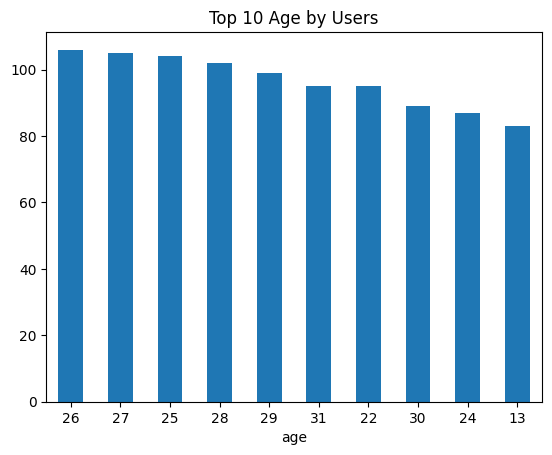

In [ ]:
# Age Group Distribution

df_pivot_age = pd.pivot_table(
    data=df,
    index='age',
    values='user_id',
    aggfunc='nunique'
).sort_values(by='user_id', ascending=False).head(10)

df_pivot_age.plot(kind='bar', title='Top 10 Age by Users', rot=0, legend=False)

<Axes: title={'center': 'Top 10 Country by Users'}, ylabel='country'>

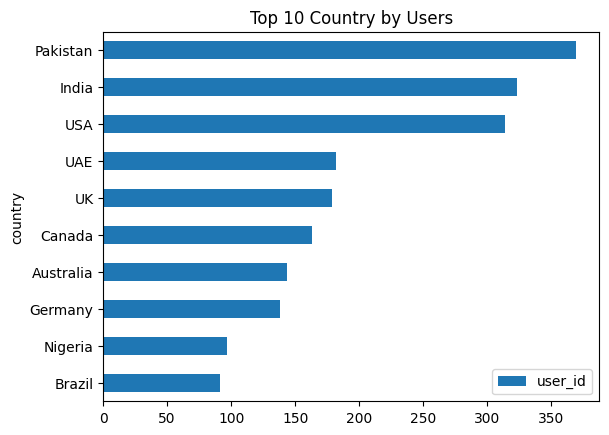

In [ ]:
# Country Distribution

df_pivot_age = pd.pivot_table(
    data=df,
    index='country',
    values='user_id',
    aggfunc='nunique'
).sort_values(by='user_id', ascending=True).head(10)

df_pivot_age.plot(kind='barh',title='Top 10 Country by Users')

<Axes: title={'center': 'Engagament by Platform'}, ylabel='primary_platform'>

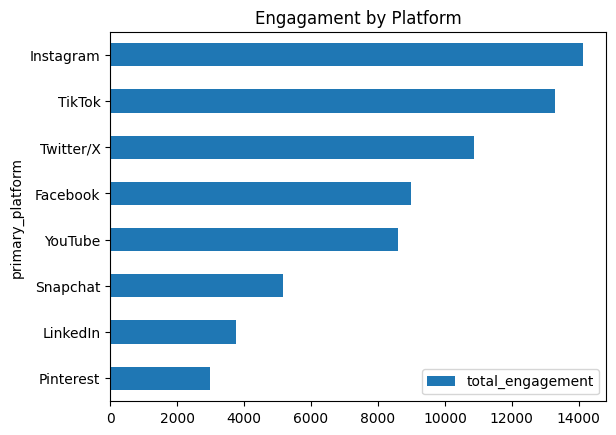

In [ ]:
# Engagement by Platform

df_pivot_plused = pd.pivot_table(
    data=df,
    index='primary_platform',
    values='total_engagement',
    aggfunc='sum'
).sort_values(by='total_engagement', ascending=True)

df_pivot_plused.plot(kind='barh',title='Engagament by Platform')

<Axes: title={'center': 'Peak Usage Time'}, ylabel='peak_usage_time'>

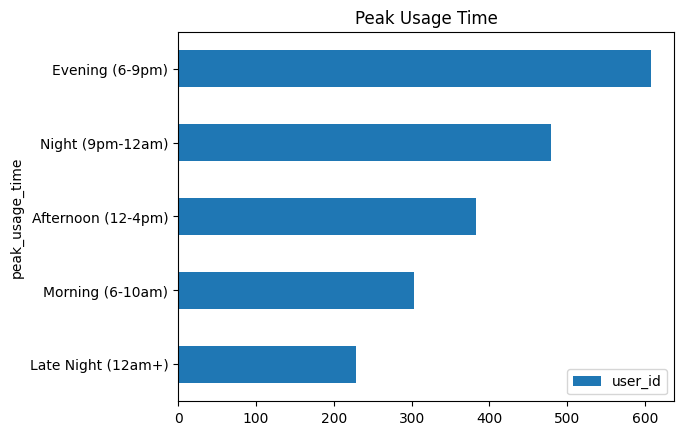

In [ ]:
# Peak Usage Time

df_pivot_plused = pd.pivot_table(
    data=df,
    index='peak_usage_time',
    values='user_id',
    aggfunc='count'
).sort_values(by='user_id', ascending=True)

df_pivot_plused.plot(kind='barh',title='Peak Usage Time')

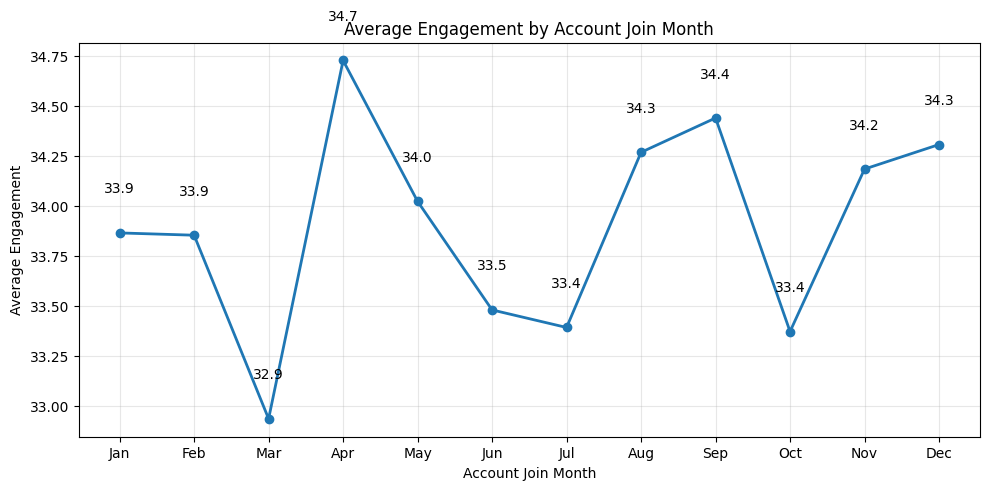

In [ ]:
# Monthly Average Engagement Trend

## Create join month
df['join_month'] = pd.to_datetime(
    df['account_join_date']
).dt.strftime('%b')

## Month order
month_order = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

## Aggregate engagement
engagement_by_month = (
    df.groupby('join_month')['total_engagement']
      .mean()
      .reindex(month_order)
      .reset_index()
)

## Visualization
plt.figure(figsize=(10,5))

plt.plot(
    engagement_by_month['join_month'],
    engagement_by_month['total_engagement'],
    marker='o',
    linewidth=2
)

## Data labels
for x, y in zip(
    engagement_by_month['join_month'],
    engagement_by_month['total_engagement']
):
    plt.text(x, y + 0.2, f'{y:.1f}', ha='center')

plt.title('Average Engagement by Account Join Month')
plt.xlabel('Account Join Month')
plt.ylabel('Average Engagement')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()